# 06 Explain the model and read its mistakes

Model: TF-IDF + logistic regression (default weights), threshold t = 0.73, both chosen on validation in notebook 05.

1. **What has the model learned?** The words with the largest weight for each product.
2. **Why did it make one specific prediction?** Which words pushed it there.
3. **Where does it go wrong?** The most common confident mistakes on test, then a sample of 30 to read by hand and group by reason.

The test set was already scored once in notebook 05. Reading its mistakes now is fine: we are explaining the result, not changing the model.

In [1]:
from pathlib import Path
import json
import textwrap

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "README.md").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "complaints_clean.csv.gz"
FIG = ROOT / "reports" / "figures"
SAMPLE_FILE = ROOT / "reports" / "06_error_sample.csv"

T = json.loads((ROOT / "reports" / "05_triage_test.json").read_text())["threshold"]
model = joblib.load(ROOT / "models" / "tfidf_logreg.joblib")
tfidf = model.named_steps["tfidf"]
clf = model.named_steps["clf"]

df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
test = df[df["split"] == "test"].reset_index(drop=True)
print("threshold:", T, "| test rows:", len(test))

SHORT = {
    "Credit reporting or other personal consumer reports": "Credit reporting",
    "Money transfer, virtual currency, or money service": "Money transfer",
    "Checking or savings account": "Checking/savings",
    "Debt collection": "Debt collection",
    "Credit card": "Credit card",
    "Mortgage": "Mortgage",
    "Student loan": "Student loan",
    "Vehicle loan or lease": "Vehicle loan",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/personal loan",
    "Other": "Other",
}

threshold: 0.73 | test rows: 42445


## 1. Top terms per product

Logistic regression keeps a matrix `coef_` with one row per product and one column per term (about 150,000). A large positive weight means "this term pushes the complaint towards this product". `get_feature_names_out()` gives the term for each column, in the same order.

Caution: a weight shows what the model *uses*, not what *causes* a complaint. Company names often show up because some companies only offer one product.

In [2]:
terms = tfidf.get_feature_names_out()
coef = clf.coef_                      # shape: (number of products, number of terms)
print(coef.shape)

TOP = 12
top_terms = {}
for k, product in enumerate(clf.classes_):
    idx = np.argsort(coef[k])[::-1][:TOP]          # columns with the largest weights, largest first
    top_terms[SHORT[product]] = [f"{terms[j]} ({coef[k, j]:.1f})" for j in idx]

pd.DataFrame(top_terms).T

(10, 151922)


,0,1,2,3,4,5,6,7,8,9,10,11
Checking/savings,deposit (7.5),overdraft (6.5),bank (6.4),funds (6.2),my account (4.9),savings (4.8),capital one (4.7),fees (4.6),account (4.5),checking (4.5),money (4.4),deposits (4.3)
Credit card,card (10.5),credit card (7.8),interest (4.1),credit (4.0),citi (3.9),synchrony (3.6),capital one (3.5),capital (3.3),discover (2.9),cards (2.9),charges (2.8),rewards (2.8)
Credit reporting,experian (8.3),equifax (7.3),credit (7.0),report (6.9),transunion (6.4),inquiries (5.3),reporting (4.5),accounts (4.4),my credit (4.4),information (3.7),inquiry (3.5),credit report (3.4)
Debt collection,debt (10.9),collection (7.1),collections (4.1),owe (3.9),credit (3.3),bill (3.1),owed (3.1),my credit (3.0),calls (2.9),llc (2.8),the debt (2.7),credit report (2.6)
Money transfer,zelle (11.4),money (7.5),cashapp (7.0),app (5.7),transactions (4.9),cash (4.8),cash app (4.7),transfer (3.6),transaction (3.6),funds (3.5),coinbase (3.3),my account (3.3)
Mortgage,mortgage (12.1),escrow (5.6),home (5.0),my mortgage (4.3),loan (4.1),foreclosure (4.1),property (3.6),payment (3.5),insurance (3.5),modification (3.3),newrez (3.0),house (2.9)
Other,card (5.5),gift (4.7),lexington (4.2),lexington law (4.0),the card (3.9),gift card (3.4),prepaid (2.7),repair (2.6),cards (2.3),services (2.3),use (2.3),to use (2.1)
Payday/personal loan,loan (7.3),the loan (4.1),interest (3.0),acima (2.5),pay (2.1),affirm (2.0),payment (1.9),payments (1.8),company (1.7),for loan (1.7),personal loan (1.6),predatory (1.4)
Student loan,mohela (8.0),loans (6.6),student (6.3),loan (5.2),school (4.7),forbearance (4.5),student loan (3.6),nelnet (3.1),my loans (3.0),forgiveness (2.8),navient (2.7),my loan (2.6)
Vehicle loan,vehicle (8.5),car (7.6),loan (4.5),the car (4.3),auto (4.0),the vehicle (3.8),finance (2.9),repossession (2.7),acceptance (2.5),dealership (2.4),auto loan (2.4),my vehicle (2.2)


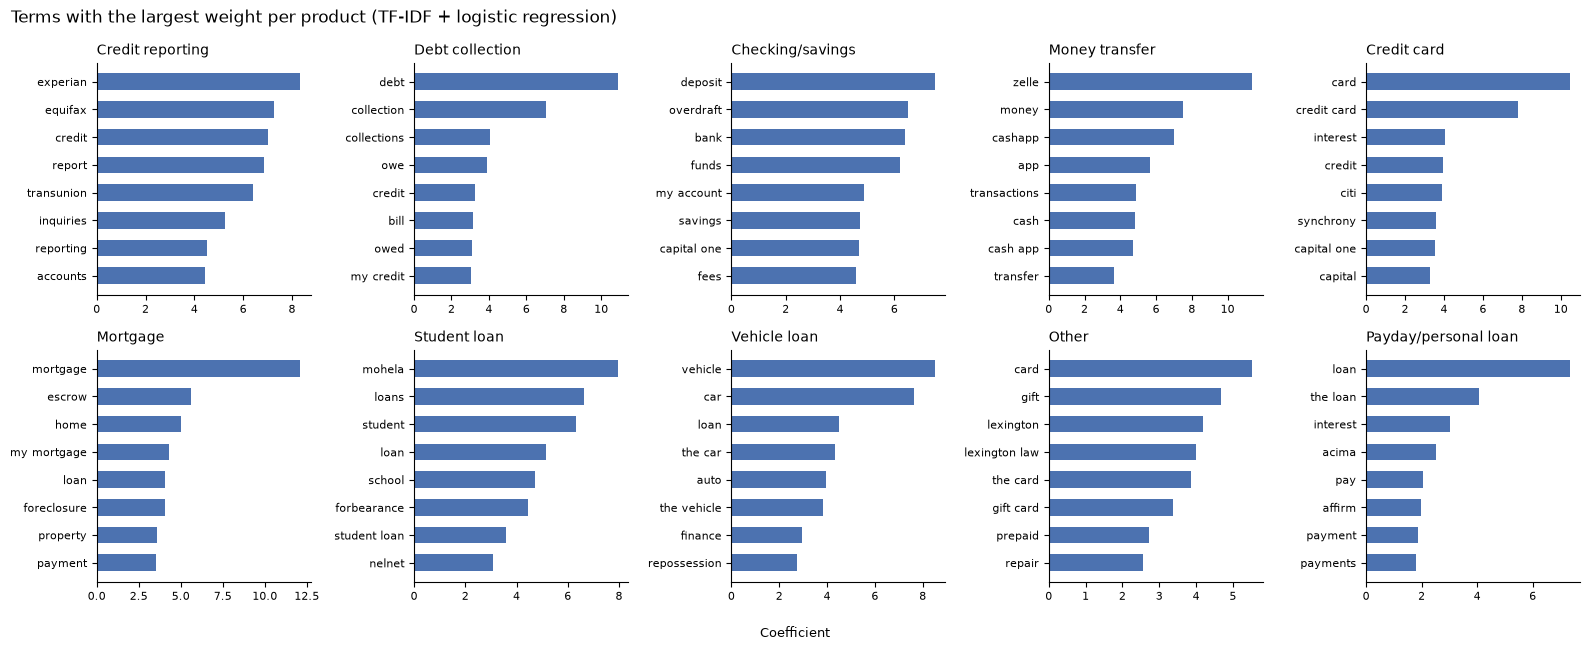

In [3]:
order = [SHORT[p] for p in test["Product"].value_counts().index]
k_of = {SHORT[p]: k for k, p in enumerate(clf.classes_)}

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for ax, name in zip(axes.flat, order):
    k = k_of[name]
    idx = np.argsort(coef[k])[::-1][:8][::-1]       # top 8, reversed so the largest is drawn at the top
    ax.barh([terms[j] for j in idx], coef[k, idx], color="#4C72B0", height=0.6)
    ax.set_title(name, fontsize=10, loc="left")
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Terms with the largest weight per product (TF-IDF + logistic regression)", x=0.01, ha="left")
fig.supxlabel("Coefficient", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "06_top_terms.png", dpi=150)
plt.show()

## 2. Explain one prediction

For logistic regression the score of a product is: intercept + sum over terms of (TF-IDF value of the term in this complaint x the term's weight for that product). So each term's **contribution** = its TF-IDF value x its weight. The terms with the largest contributions are the reasons for the prediction.

`transform` returns a sparse matrix (mostly zeros); `.nonzero()` gives the columns of the terms that actually appear.

In [4]:
proba = model.predict_proba(test["text"])
pred = clf.classes_[proba.argmax(axis=1)]
conf = proba.max(axis=1)
test["pred"] = pred
test["conf"] = conf
test["correct"] = test["pred"] == test["Product"]
test["auto"] = test["conf"] >= T

def explain(i, n=10):
    row = test.loc[i]
    x = tfidf.transform([row["text"]])
    cols = x.nonzero()[1]
    k = list(clf.classes_).index(row["pred"])
    contrib = pd.Series(x[0, cols].toarray().ravel() * coef[k, cols], index=terms[cols])
    print(f"true: {SHORT[row['Product']]} | predicted: {SHORT[row['pred']]} | confidence {row['conf']:.2f}")
    print(textwrap.fill(row["text"][:500], 110), "\n")
    print(f"terms pushing towards {SHORT[row['pred']]}:")
    print(contrib.sort_values(ascending=False).head(n).round(3).to_string())

# A confident mistake: auto-routed but wrong, with a true product of Payday/personal loan if there is one
mistakes = test[test["auto"] & ~test["correct"]]
payday = mistakes[mistakes["Product"].str.startswith("Payday")]
explain((payday if len(payday) else mistakes).index[0])

true: Payday/personal loan | predicted: Credit reporting | confidence 0.85
I pull my credit report from experience and noticed that I had a account on there from / / that has been
closed and charged off so I called and asked if they could remove it off my credit report and they said it
would have to stay on there for seven years when I know thats not right 

terms pushing towards Credit reporting:
report           0.401
credit           0.361
my credit        0.274
off              0.237
credit report    0.221
pull             0.152
report from      0.149
charged off      0.125
on there         0.116
report and       0.104


## 3. Confident mistakes on test

These matter most for the business: the model was sure (confidence >= t), so the complaint went to the wrong team with no human check.

In [5]:
print(f"auto-routed: {test['auto'].sum():,} | of which wrong: {len(mistakes):,} "
      f"({len(mistakes) / test['auto'].sum():.1%})")

(mistakes.assign(true=mistakes["Product"].map(SHORT), predicted=mistakes["pred"].map(SHORT))
   .groupby(["true", "predicted"]).size().rename("complaints")
   .sort_values(ascending=False).head(10).to_frame())

auto-routed: 27,819 | of which wrong: 1,834 (6.6%)


,,complaints
true,predicted,
Debt collection,Credit reporting,791
Credit reporting,Debt collection,248
Credit card,Credit reporting,198
Student loan,Credit reporting,87
Checking/savings,Money transfer,72
Vehicle loan,Credit reporting,67
Money transfer,Checking/savings,60
Other,Credit reporting,46
Checking/savings,Credit reporting,36


## 4. A sample to read by hand

Up to 3 confident mistakes per true product (30 in total), picked at random with a fixed seed so the sample is the same every run. Stratifying by product makes sure the small products are in the sample, not only Credit reporting.

Each complaint was read and given one reason in the `reason` column of `reports/06_error_sample.csv` (with a short `note`):
- `ambiguous`: honestly could be either product
- `multi-product`: the complaint is about two products (for example a payday loan now with a debt collector)
- `label noise`: the consumer picked the wrong product; the model is arguably right
- `template`: a copy-paste text that says little about the product
- `model error`: the text is clear and the model is simply wrong
- `truncated/short`: too little text to tell

The cell below writes the file **only if it does not exist yet**, so re-running the notebook never overwrites the reasons.

In [6]:
# Shuffle all mistakes once (fixed seed), then keep the first 3 of each true product.
sample = (mistakes.sample(frac=1, random_state=42)
                  .groupby("Product").head(3)
                  .sort_values(["Product", "conf"], ascending=[True, False])
                  .assign(true=lambda d: d["Product"].map(SHORT),
                          predicted=lambda d: d["pred"].map(SHORT),
                          conf=lambda d: d["conf"].round(2),
                          reason="")
                  [["Complaint ID", "true", "predicted", "conf", "Issue", "Company", "text", "reason"]])
print(len(sample), "complaints in the sample")

if not SAMPLE_FILE.exists():
    sample.to_csv(SAMPLE_FILE, index=False)
    print("written:", SAMPLE_FILE)
else:
    print("already exists, not overwritten:", SAMPLE_FILE)

30 complaints in the sample
already exists, not overwritten: C:\Projects\complaint-triage\reports\06_error_sample.csv


In [7]:
for _, r in sample.iterrows():
    print(f"[{r['Complaint ID']}] true: {r['true']} | predicted: {r['predicted']} | conf {r['conf']} | issue: {r['Issue']}")
    print(textwrap.fill(r["text"][:600], 110))
    print("-" * 110)

[11931985] true: Checking/savings | predicted: Money transfer | conf 0.78 | issue: Problem with a lender or other company charging your account
I have tried for months to get my account correct with Cash app. Try contacting customer service for months.
My account was hacked and put me in the negative. I open up another account and it happened again. Money was
taken from both accounts and somehow they got into my Chase Bank as well. Customer service never responded.
--------------------------------------------------------------------------------------------------------------
[12145977] true: Checking/savings | predicted: Credit card | conf 0.78 | issue: Closing an account
Every week I need to call Chase Bank due to credit card issues or checking account issues. They are constantly
dealing with fraudulent charges on my credit cards. The fraud claim I filed more than 2 months ago was just
ignored. I finally decided to cancel my account. I updated all credit card payments to be paid from .

## 5. Tally the reasons

In [8]:
filled = pd.read_csv(SAMPLE_FILE, dtype=str, keep_default_na=False)
done = filled[filled["reason"].str.strip() != ""]
print(f"{len(done)} of {len(filled)} have a reason")
if len(done):
    display(done["reason"].str.strip().str.lower().value_counts().to_frame("complaints"))

30 of 30 have a reason


,complaints
reason,
multi-product,13
label noise,7
template,4
ambiguous,3
model error,2
truncated/short,1
